In [122]:
import numpy as np
import matplotlib.pyplot as plt

In [123]:
# Unidades

## Comprimento
um = 1e-6
nm = 1e-9

## Frequência

GHz = 1e9
THz = 1e12

## Tempo

ns = 1e-9
ps = 1e-12

# Constantes

pi = np.pi
c = 3e8 # m/s
lambda0 = 1.55*um
f0 = c/lambda0

## Parametros do guia de onda

w = 500*nm
h = 220*nm

neff = 2.4455
ng = 4.1909

# Mapas de cores

cmap1 = plt.cm.viridis
cmap2 = plt.cm.plasma
cmap3 = plt.cm.inferno
cmap4 = plt.cm.magma
cmap5 = plt.cm.coolwarm
cmap6 = plt.cm.turbo
cmap7 = plt.cm.GnBu
cmap8 = plt.cm.winter

# Projeto - Filtro de Vernier #

Projeto de um filtro de Vernier sintonizável na banda C ($1530-1565\,nm$). Adotando ressonância inicial em $1550\,nm$. Parâmetros:

1) $FSR_{ef}>35\,nm$;
2) $FSHM=25\,GHz$ ($0,20\,nm$) por anel;
3) supressão de espúrios $\geq 25\,dB$;
4) guia $500\times 220\,nm$ ($n_{eff}=2,4455$, $n_g=4,1909$, $\alpha_{dB}=3\,dB/cm$);
6) Aneis circulares, acopladores simétricos.

Das especificações, extraimos:

1 - Comprimento:

Escolhendo $N_1 = 4$ e $N_2 = 5$:

$$\frac{m_1}{m_2}=\frac{N_1}{N_2}\rightarrow m_1 = 100\,,\,m_2=125\,$$
$$L = \frac{m\lambda_0}{n_{eff}}\rightarrow L_1\approx 63,38\,\mu m\,,\,L_2\approx 79,23\,\mu m\,.$$

2 - FSR e supressão de espúrios

$$FSR_\lambda=\frac{{\lambda_0}^2}{n_g L}\rightarrow FSR_1\approx 9,045\,nm\,,\,FSR_2\approx 7,235\,nm\,;$$
$$\Delta = |FSR_1 - FSR_2|\approx 1,810\,nm$$
$$\frac{T_{d2}(\Delta)}{T_{d2}(0)}\approx 10\log_{10}\left(\frac{1}{1+(2\Delta/FWHM)^2}\right)\approx-25,17\,dB\,;$$

3 - Perdas no guia

$$a=10^{-\alpha_{dB}L/20}\rightarrow a_1\approx 0,9978\,,\,a_2\approx 0,9973\,;$$

4 - Finesse e autoacoplamento

$$\mathcal{F}=\frac{FSR}{FWHM}\rightarrow \mathcal{F}_1\approx 45,146\,,\,\mathcal{F}_2\approx 36,114$$

$$x=\left(\frac{-\pi+\sqrt{\pi^2+4\mathcal{F}^2}}{2\mathcal{F}}\right)^2\rightarrow x_1\approx 0,9328\,,\,x_2\approx 0,9167$$
$$r=\sqrt{\frac{x}{a}}\rightarrow r_1\approx 0,9669\,,\,r_2\approx 0,9587\,;$$

5 - Transmissão máxima na ressonância

$$T_d(\phi=0)=10\log_{10}\left[\frac{(1-r^2)^2a}{(1-r^2a)^2}\right]\rightarrow T_{d1}(\phi=0)\approx-0,28\,dB\,,\,T_{d2}(\phi=0)\approx-0,27\,dB\,.$$


In [124]:
def neff_lambda(lambda_, n_eff = neff, n_g = ng):
    neff_ = n_g + lambda_*(n_eff-n_g)/lambda0
    return neff_

def phi(lambda_, L, n_eff=neff):
    num = 2*pi*neff_lambda(lambda_, n_eff)*L
    den = lambda_
    return num/den

def T_p(phi,r1,r2,a):
    num = r1**2 - 2*r1*r2*a*np.cos(phi) + (r2*a)**2
    den = 1 - 2*r1*r2*a*np.cos(phi) + (r1*r2*a)**2
    return num/den

def T_d(phi,r1,r2,a):
    num = (1 - r1**2)*(1 - r2**2)*a
    den = 1 - 2*r1*r2*a*np.cos(phi) + (r1*r2*a)**2
    return num/den

In [125]:
L1 = 63.38*um
L2 = 79.23*um

a1 = 0.9978
a2 = 0.9973

r1 = 0.9669
r2 = 0.9587

lambda_array = np.linspace(1500, 1600, 5001)*nm

phi_array1 = phi(lambda_array, L1)
phi_array2 = phi(lambda_array, L2)

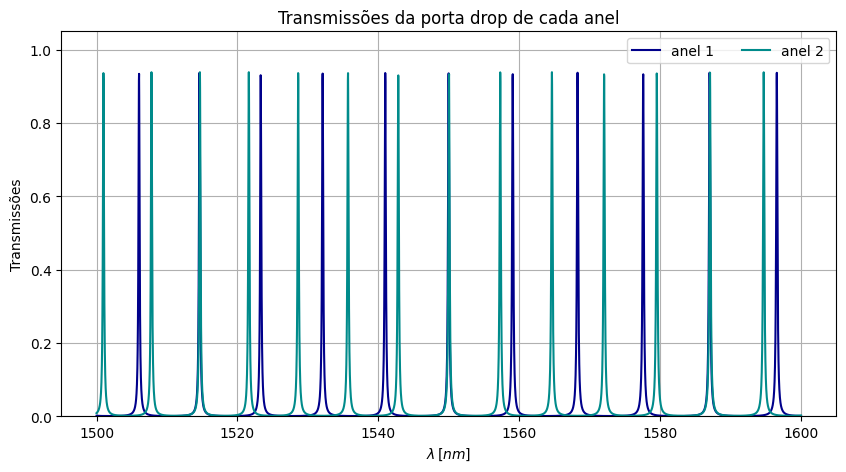

In [126]:
Td1 = T_d(phi_array1, r1, r1, a1)
Td2 = T_d(phi_array2, r2, r2, a2)


plt.figure(figsize = (10,5))
plt.plot(lambda_array/nm, Td1, color = 'darkblue', label = 'anel 1')
plt.plot(lambda_array/nm, Td2, color = 'darkcyan', label = 'anel 2')
plt.grid(True)
plt.legend(loc = 'upper right', ncols = 2)
plt.xlabel(r'$\lambda\,[nm]$')
plt.ylabel(r'Transmissões')
plt.title('Transmissões da porta drop de cada anel')
plt.ylim([0, 1.05])
#plt.axvline(1550, color = 'red', linestyle = '--', linewidth = 0.75)
#plt.axvline(1550+9.045, color = 'red', linestyle = '--', linewidth = 0.75)
#plt.axvline(1550-7.235, color = 'red', linestyle = '--', linewidth = 0.75)
plt.show()

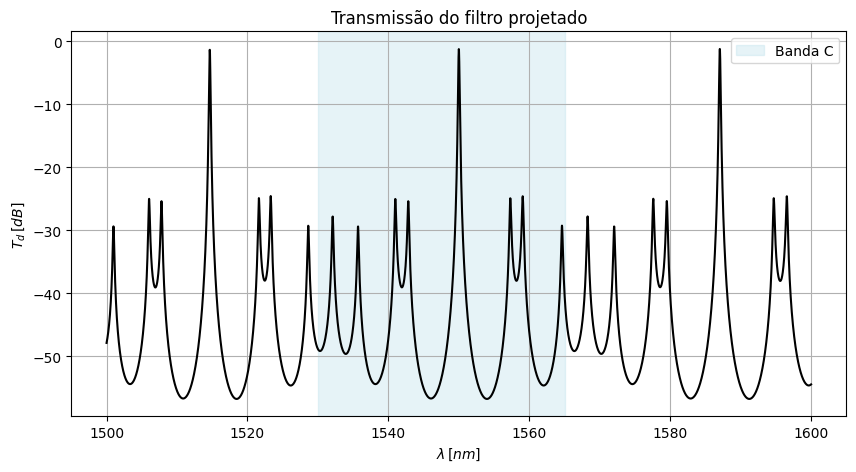

In [127]:
Td = Td1*Td2

plt.figure(figsize = (10,5))
plt.plot(lambda_array/nm, 10*np.log10(Td), color = 'black')
#plt.plot(lambda_array/nm, Td, color = 'black')
plt.grid(True)
plt.xlabel(r'$\lambda\,[nm]$')
plt.ylabel(r'$T_d\,[dB]$')
plt.title('Transmissão do filtro projetado')
plt.axvspan(1530, 1565, color = 'lightblue', alpha = 0.3, label = 'Banda C')
#plt.axvline(1550, color = 'red', linestyle = '--', linewidth = 0.75)
#plt.axvline(1550+36.9, color = 'red', linestyle = '--', linewidth = 0.75)
#plt.axvline(1550-35.5, color = 'red', linestyle = '--', linewidth = 0.75)
#plt.axhline(-25.17, color = 'red', linestyle = '--', linewidth = 0.75)
plt.legend(loc = 'upper right')
plt.show()